**Ketan Nikam**

**126M1B011**
# Experiment 2: Implement POS Tagging Using spaCy
**NLP Lab – M.Tech**

## Import Libraries

In [1]:
import spacy
import pandas as pd
import matplotlib.pyplot as plt

print("spaCy version:", spacy.__version__)
print("pandas version:", pd.__version__)

nlp = spacy.load("en_core_web_sm")
print("English model loaded successfully.")

spaCy version: 3.8.4
pandas version: 2.2.3
English model loaded successfully.


## Step 1 – Enter the input text
The sample text follows the experiment handout and includes nouns, verbs, adjectives, auxiliaries, and time expressions.

In [9]:
text =  """
Artificial intelligence is transforming the way people work and learn.
The engineers are designing intelligent machines, and the scientists are
conducting experiments to improve their performance.
Students write programs, analyze results, and discuss new ideas.
A computer can process information quickly, but it cannot always understand
the meaning of human communication.
The team will present its findings next week.
""".strip()

print(text)
print("\nCharacter count:", len(text))

Artificial intelligence is transforming the way people work and learn.
The engineers are designing intelligent machines, and the scientists are
conducting experiments to improve their performance.
Students write programs, analyze results, and discuss new ideas.
A computer can process information quickly, but it cannot always understand
the meaning of human communication.
The team will present its findings next week.

Character count: 419


## Step 2 – Process the text with spaCy

In [10]:
doc = nlp(text)

print("Text processed successfully.")
print("Number of tokens:", len(doc))
print("Tokens:", [token.text for token in doc])

Text processed successfully.
Number of tokens: 75
Tokens: ['Artificial', 'intelligence', 'is', 'transforming', 'the', 'way', 'people', 'work', 'and', 'learn', '.', '\n', 'The', 'engineers', 'are', 'designing', 'intelligent', 'machines', ',', 'and', 'the', 'scientists', 'are', '\n', 'conducting', 'experiments', 'to', 'improve', 'their', 'performance', '.', '\n', 'Students', 'write', 'programs', ',', 'analyze', 'results', ',', 'and', 'discuss', 'new', 'ideas', '.', '\n', 'A', 'computer', 'can', 'process', 'information', 'quickly', ',', 'but', 'it', 'can', 'not', 'always', 'understand', '\n', 'the', 'meaning', 'of', 'human', 'communication', '.', '\n', 'The', 'team', 'will', 'present', 'its', 'findings', 'next', 'week', '.']


## Step 3 – Display each token and its coarse POS tag

In [11]:
for token in doc:
    print(f"{token.text:15} -> {token.pos_}")

Artificial      -> ADJ
intelligence    -> NOUN
is              -> AUX
transforming    -> VERB
the             -> DET
way             -> NOUN
people          -> NOUN
work            -> VERB
and             -> CCONJ
learn           -> VERB
.               -> PUNCT

               -> SPACE
The             -> DET
engineers       -> NOUN
are             -> AUX
designing       -> VERB
intelligent     -> ADJ
machines        -> NOUN
,               -> PUNCT
and             -> CCONJ
the             -> DET
scientists      -> NOUN
are             -> AUX

               -> SPACE
conducting      -> VERB
experiments     -> NOUN
to              -> PART
improve         -> VERB
their           -> PRON
performance     -> NOUN
.               -> PUNCT

               -> SPACE
Students        -> NOUN
write           -> VERB
programs        -> NOUN
,               -> PUNCT
analyze         -> VERB
results         -> NOUN
,               -> PUNCT
and             -> CCONJ
discuss         -> VERB
new          

### POS table

In [12]:
pos_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc]
})
display(pos_table)

,Token,POS
0,Artificial,ADJ
1,intelligence,NOUN
2,is,AUX
3,transforming,VERB
4,the,DET
...,...,...
70,its,PRON
71,findings,NOUN
72,next,ADJ
73,week,NOUN


## Step 4 – Display detailed POS tags

In [13]:
detailed_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
    "Tag": [token.tag_ for token in doc]
})
display(detailed_table)

,Token,POS,Tag
0,Artificial,ADJ,JJ
1,intelligence,NOUN,NN
2,is,AUX,VBZ
3,transforming,VERB,VBG
4,the,DET,DT
...,...,...,...
70,its,PRON,PRP$
71,findings,NOUN,NNS
72,next,ADJ,JJ
73,week,NOUN,NN


## Step 5 – Display POS, lemma, and morphology

In [14]:
analysis_table = pd.DataFrame({
    "Token": [token.text for token in doc],
    "POS": [token.pos_ for token in doc],
    "Tag": [token.tag_ for token in doc],
    "Lemma": [token.lemma_ for token in doc],
    "Morphology": [str(token.morph) for token in doc]
})
display(analysis_table)

,Token,POS,Tag,Lemma,Morphology
0,Artificial,ADJ,JJ,artificial,Degree=Pos
1,intelligence,NOUN,NN,intelligence,Number=Sing
2,is,AUX,VBZ,be,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...
3,transforming,VERB,VBG,transform,Aspect=Prog|Tense=Pres|VerbForm=Part
4,the,DET,DT,the,Definite=Def|PronType=Art
...,...,...,...,...,...
70,its,PRON,PRP$,its,Gender=Neut|Number=Sing|Person=3|Poss=Yes|Pron...
71,findings,NOUN,NNS,finding,Number=Plur
72,next,ADJ,JJ,next,Degree=Pos
73,week,NOUN,NN,week,Number=Sing


## Step 6 – Analyze alphabetic words only

In [15]:
word_table = pd.DataFrame({
    "Token": [t.text for t in doc if t.is_alpha],
    "POS": [t.pos_ for t in doc if t.is_alpha],
    "Tag": [t.tag_ for t in doc if t.is_alpha],
    "Lemma": [t.lemma_ for t in doc if t.is_alpha]
})
display(word_table)

,Token,POS,Tag,Lemma
0,Artificial,ADJ,JJ,artificial
1,intelligence,NOUN,NN,intelligence
2,is,AUX,VBZ,be
3,transforming,VERB,VBG,transform
4,the,DET,DT,the
5,way,NOUN,NN,way
6,people,NOUN,NNS,people
7,work,VERB,VBP,work
8,and,CCONJ,CC,and
9,learn,VERB,VBP,learn


## Step 7 – Count the frequency of each POS category

In [16]:
pos_counts = (
    word_table["POS"]
    .value_counts()
    .rename_axis("POS")
    .reset_index(name="Count")
)
display(pos_counts)

,POS,Count
0,NOUN,19
1,VERB,12
2,DET,6
3,AUX,6
4,ADJ,5
5,CCONJ,4
6,PRON,3
7,PART,2
8,ADV,2
9,ADP,1


### visualization: POS tag distribution

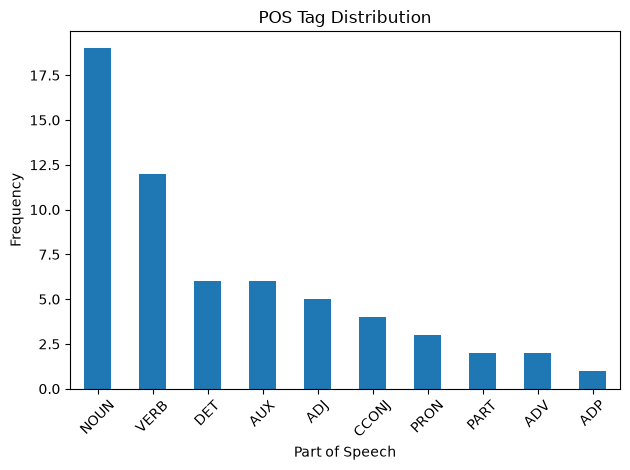

In [18]:
ax = pos_counts.plot(
    kind="bar",
    x="POS",
    y="Count",
    legend=False,
    title="POS Tag Distribution",
    rot=45
)
ax.set_xlabel("Part of Speech")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 8 – Test context-dependent POS tagging

In [19]:
sentences = [
    "I read a book every week.",
    "Please book a ticket for tomorrow.",
    "They watch the match.",
    "They match the colors carefully.",
    "The light is bright.",
    "Please light the lamp."
]

for sentence in sentences:
    print("\\nSentence:", sentence)
    sentence_doc = nlp(sentence)
    for token in sentence_doc:
        if token.text.lower() in {"book", "match", "light"}:
            print(
                f"{token.text:10} POS={token.pos_:8} "
                f"TAG={token.tag_:8} LEMMA={token.lemma_}"
            )

\nSentence: I read a book every week.
book       POS=NOUN     TAG=NN       LEMMA=book
\nSentence: Please book a ticket for tomorrow.
book       POS=VERB     TAG=VB       LEMMA=book
\nSentence: They watch the match.
match      POS=NOUN     TAG=NN       LEMMA=match
\nSentence: They match the colors carefully.
match      POS=VERB     TAG=VBP      LEMMA=match
\nSentence: The light is bright.
light      POS=NOUN     TAG=NN       LEMMA=light
\nSentence: Please light the lamp.
light      POS=VERB     TAG=VB       LEMMA=light


## Step 9 – Create a final POS analysis table grouped by sentence

In [20]:
final_table = pd.DataFrame([
    {
        "Sentence": token.sent.text.strip(),
        "Token": token.text,
        "POS": token.pos_,
        "Tag": token.tag_,
        "Lemma": token.lemma_,
        "Morphology": str(token.morph)
    }
    for token in doc
])
display(final_table)

,Sentence,Token,POS,Tag,Lemma,Morphology
0,Artificial intelligence is transforming the wa...,Artificial,ADJ,JJ,artificial,Degree=Pos
1,Artificial intelligence is transforming the wa...,intelligence,NOUN,NN,intelligence,Number=Sing
2,Artificial intelligence is transforming the wa...,is,AUX,VBZ,be,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...
3,Artificial intelligence is transforming the wa...,transforming,VERB,VBG,transform,Aspect=Prog|Tense=Pres|VerbForm=Part
4,Artificial intelligence is transforming the wa...,the,DET,DT,the,Definite=Def|PronType=Art
...,...,...,...,...,...,...
70,The team will present its findings next week.,its,PRON,PRP$,its,Gender=Neut|Number=Sing|Person=3|Poss=Yes|Pron...
71,The team will present its findings next week.,findings,NOUN,NNS,finding,Number=Plur
72,The team will present its findings next week.,next,ADJ,JJ,next,Degree=Pos
73,The team will present its findings next week.,week,NOUN,NN,week,Number=Sing


## Step 10 – Result table and interpretation

The following table summarizes the POS categories present in the alphabetic words of the input text. Frequencies depend on the exact text and spaCy model version.

In [21]:
example_tokens = (
    word_table.groupby("POS")["Token"]
    .apply(lambda values: ", ".join(values.head(5)))
    .rename("Example Tokens")
)
result_table = pos_counts.merge(example_tokens, on="POS", how="left")
result_table["My Interpretation"] = result_table["POS"].map({
    "NOUN": "Common objects, concepts, or people",
    "PROPN": "Specific names or named entities",
    "VERB": "Actions or processes",
    "AUX": "Auxiliary/helping verbs",
    "ADJ": "Describes a noun",
    "ADV": "Modifies a verb, adjective, or adverb",
    "PRON": "Replaces or refers to a noun phrase",
    "DET": "Introduces/specifies a noun",
    "ADP": "Expresses relations such as place or time",
    "CCONJ": "Connects equivalent words or clauses",
    "SCONJ": "Introduces a dependent clause",
    "NUM": "Numerical expression",
    "PART": "Particle, e.g. infinitival 'to' or negation",
    "INTJ": "Interjection"
}).fillna("Other grammatical category")
display(result_table)

,POS,Count,Example Tokens,My Interpretation
0,NOUN,19,"intelligence, way, people, engineers, machines","Common objects, concepts, or people"
1,VERB,12,"transforming, work, learn, designing, conducting",Actions or processes
2,DET,6,"the, The, the, A, the",Introduces/specifies a noun
3,AUX,6,"is, are, are, can, can",Auxiliary/helping verbs
4,ADJ,5,"Artificial, intelligent, new, human, next",Describes a noun
5,CCONJ,4,"and, and, and, but",Connects equivalent words or clauses
6,PRON,3,"their, it, its",Replaces or refers to a noun phrase
7,PART,2,"to, not","Particle, e.g. infinitival 'to' or negation"
8,ADV,2,"quickly, always","Modifies a verb, adjective, or adverb"
9,ADP,1,of,Expresses relations such as place or time


### Automatically generated observations

In [23]:
if not pos_counts.empty:
    highest = pos_counts.iloc[0]
    lowest_count = pos_counts["Count"].min()
    least_common = pos_counts.loc[pos_counts["Count"] == lowest_count, "POS"].tolist()
    print(f"Most frequent POS category: {highest['POS']} ({highest['Count']} tokens)")
    print(f"Least frequent category/categories among those present: {', '.join(least_common)} ({lowest_count} tokens)")

print("\\nExamples by category:")
for category in ["NOUN", "PROPN", "VERB", "AUX", "ADJ", "ADV"]:
    words = word_table.loc[word_table["POS"] == category, "Token"].tolist()
    if words:
        print(f"{category}: {', '.join(words)}")


Most frequent POS category: NOUN (19 tokens)
Least frequent category/categories among those present: ADP (1 tokens)
\nExamples by category:
NOUN: intelligence, way, people, engineers, machines, scientists, experiments, performance, Students, programs, results, ideas, computer, information, meaning, communication, team, findings, week
VERB: transforming, work, learn, designing, conducting, improve, write, analyze, discuss, process, understand, present
AUX: is, are, are, can, can, will
ADJ: Artificial, intelligent, new, human, next
ADV: quickly, always
